# Proyecto AFORE, 03: rendimiento real

Los rendimientos del archivo son nominales, o sea que no dicen cuánto alcanza el dinero. Ganar 8% con una inflación de 7% casi no es ganar nada. Aquí los paso a rendimiento real.

Preguntas: si los plazos de 24, 36 meses y 5 años están anualizados (hay que saberlo para compararlos con la inflación), cuánto rindieron las AFOREs en términos reales, cuándo fue negativo ese rendimiento y si cambia el ranking al descontar la inflación.

La inflación sale del INPC mensual de INEGI (base 2a quincena de julio 2018 = 100), que capturé en `data/inpc_mensual.csv` desde una tabla histórica publicada por El Contribuyente. No es un archivo descargado de INEGI, por eso abajo lo comparo con la inflación anual oficial. Aun así conviene contrastarlo con el sitio de INEGI antes de publicar.

In [1]:
import sys, os
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from limpieza import (cargar_y_limpiar, cargar_inpc, agregar_real, inflacion_anualizada,
                      AFORES, PLAZOS, MESES_PLAZO)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
os.makedirs("../images/03", exist_ok=True)

DATA_AFORE = "../data/10_rendimientos_precio_bolsa.csv"
DATA_INPC = "../data/inpc_mensual.csv"

def guardar(nombre):
    plt.savefig(f"../images/03/{nombre}.png", dpi=150, bbox_inches="tight")

df, gen, sistema = cargar_y_limpiar(DATA_AFORE)
print("filas:", len(df), "| gen:", len(gen), "| sistema:", len(sistema))

filas: 38179 | gen: 23360 | sistema: 2628


## 1. Cargar y revisar el INPC

In [2]:
inpc = cargar_inpc(DATA_INPC)
print("meses:", len(inpc), "|", inpc.index.min().date(), "a", inpc.index.max().date(), "| nulos:", int(inpc.isna().sum()))

# inflación anual diciembre contra diciembre que publicó INEGI
oficial = {2017: 6.77, 2018: 4.83, 2019: 2.83, 2020: 3.15, 2021: 7.36, 2022: 7.82, 2023: 4.66, 2024: 4.21}
chk = pd.DataFrame({
    "calculada": {y: (inpc[f"{y}-12-01"] / inpc[f"{y-1}-12-01"] - 1) * 100 for y in oficial},
    "oficial": oficial,
}).round(2)
chk["coincide"] = (chk["calculada"] - chk["oficial"]).abs() < 0.01
display(chk)
print("inflación dic/dic 2025 (calculada):", round((inpc["2025-12-01"] / inpc["2024-12-01"] - 1) * 100, 2), "%")

meses: 120 | 2016-01-01 a 2025-12-01 | nulos: 0


,calculada,oficial,coincide
2017,6.77,6.77,True
2018,4.83,4.83,True
2019,2.83,2.83,True
2020,3.15,3.15,True
2021,7.36,7.36,True
2022,7.82,7.82,True
2023,4.66,4.66,True
2024,4.21,4.21,True


inflación dic/dic 2025 (calculada): 3.69 %


## 2. Si los plazos largos están anualizados
Si el rendimiento a 24 meses está anualizado, tiene que ser la media geométrica de dos rendimientos consecutivos a 12 meses: (1 + r24)^2 = (1 + r12 de hoy) x (1 + r12 de hace un año). Si fuera acumulado sería directamente el producto. Pruebo las dos opciones con los datos.

In [3]:
def prueba_anualizado(sub):
    r12 = sub.pivot(index="fecha", columns="afore", values="12 meses") / 100
    out = {}
    r24 = sub.pivot(index="fecha", columns="afore", values="24 meses") / 100
    prod2 = (1 + r12) * (1 + r12.shift(12))
    out["24m si es anualizado"] = (r24 - (prod2 ** (1 / 2) - 1)).abs().stack() * 100
    out["24m si es acumulado"] = (r24 - (prod2 - 1)).abs().stack() * 100
    r36 = sub.pivot(index="fecha", columns="afore", values="36 meses") / 100
    prod3 = prod2 * (1 + r12.shift(24))
    out["36m si es anualizado"] = (r36 - (prod3 ** (1 / 3) - 1)).abs().stack() * 100
    r60 = sub.pivot(index="fecha", columns="afore", values="5 años") / 100
    prod5 = prod3 * (1 + r12.shift(36)) * (1 + r12.shift(48))
    out["5 años si es anualizado"] = (r60 - (prod5 ** (1 / 5) - 1)).abs().stack() * 100
    return pd.DataFrame({k: v.describe()[["count", "mean", "max"]] for k, v in out.items()}).T

sub = (gen[gen["fondo"] == "90-94"]
       .pivot_table(index=["fecha", "afore"], columns="plazo", values="monto").reset_index())
prueba = prueba_anualizado(sub)
prueba.columns = ["casos", "error_promedio_pp", "error_maximo_pp"]
prueba.round(3)

,casos,error_promedio_pp,error_maximo_pp
24m si es anualizado,610.0,0.007,0.055
24m si es acumulado,610.0,8.443,23.444
36m si es anualizado,490.0,0.009,0.039
5 años si es anualizado,250.0,0.007,0.021


Con la hipótesis de anualizado el error es de centésimas de punto (redondeo), y con la de acumulado es de varios puntos. Entonces los plazos de 24, 36 meses y 5 años están anualizados. Cuadra con un aviso de Principal que dice que CONSAR reporta el rendimiento a 36 meses en términos anualizados.

## 3. Calcular el rendimiento real
Para un plazo de n meses uso la inflación anualizada, (INPC hoy / INPC hace n meses)^(12/n) - 1, y el rendimiento real es (1 + nominal) / (1 + inflación) - 1. Como mi INPC empieza en 2016, el rendimiento real a 5 años solo existe desde 2021.

In [4]:
gen_r = agregar_real(gen, inpc)
sis_r = agregar_real(sistema, inpc)

print("datos de rendimiento real por plazo:")
print(gen_r.groupby("plazo")["real"].count().to_string())

ejemplo = gen_r[(gen_r["fondo"] == "90-94") & (gen_r["afore"] == "inbursa") & (gen_r["fecha"] == gen_r["fecha"].max())]
display(ejemplo[["plazo", "monto", "inflacion", "real"]].round(2).set_index("plazo"))

datos de rendimiento real por plazo:
plazo
12 meses    5840
24 meses    5840
36 meses    5840
5 años      4800


,monto,inflacion,real
plazo,,,
12 meses,17.62,3.69,13.43
24 meses,11.74,3.95,7.49
36 meses,10.67,4.19,6.22
5 años,8.40,5.53,2.71


## 4. Nominal contra real en el tiempo (promedio del sistema, SB 90-94)

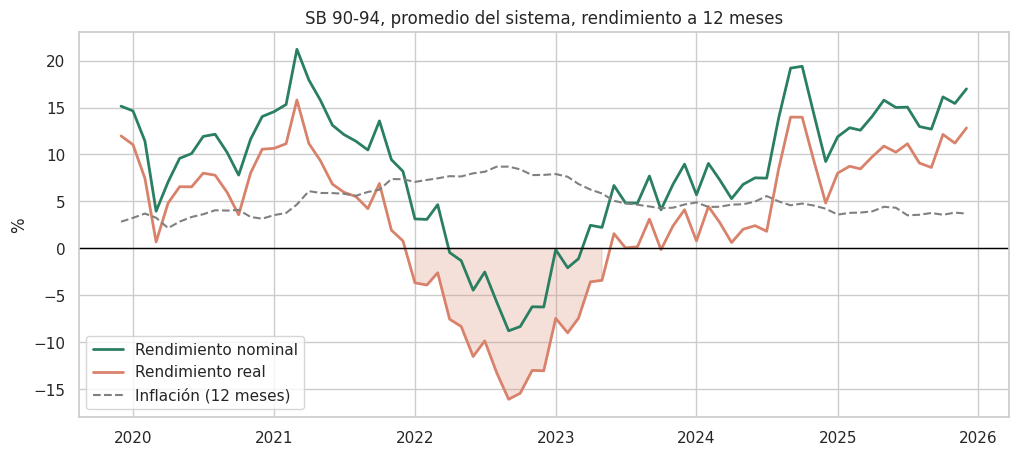

meses con rendimiento real negativo (12 meses): 18 de 73
primero: 2022-01-01 | último: 2023-10-01
peor real a 12 meses: -16.1 % en 2022-09


In [5]:
s = sis_r[(sis_r["fondo"] == "90-94") & (sis_r["plazo"] == "12 meses")].set_index("fecha").sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(s.index, s["monto"], label="Rendimiento nominal", lw=2, color="#2a7f62")
ax.plot(s.index, s["real"], label="Rendimiento real", lw=2, color="#d9826b")
ax.plot(s.index, s["inflacion"], label="Inflación (12 meses)", lw=1.5, ls="--", color="gray")
ax.fill_between(s.index, s["real"], 0, where=(s["real"] < 0), color="#d9826b", alpha=0.25)
ax.axhline(0, color="black", lw=1)
ax.set_title("SB 90-94, promedio del sistema, rendimiento a 12 meses")
ax.set_ylabel("%")
ax.set_xlabel("")
ax.legend()
guardar("01_nominal_vs_real_12m")
plt.show()

neg = s[s["real"] < 0]
print(f"meses con rendimiento real negativo (12 meses): {len(neg)} de {len(s)}")
print("primero:", neg.index.min().date(), "| último:", neg.index.max().date())
print("peor real a 12 meses:", round(s["real"].min(), 2), "% en", s["real"].idxmin().strftime("%Y-%m"))

## 5. Rendimiento real por AFORE (SB 90-94, último mes)

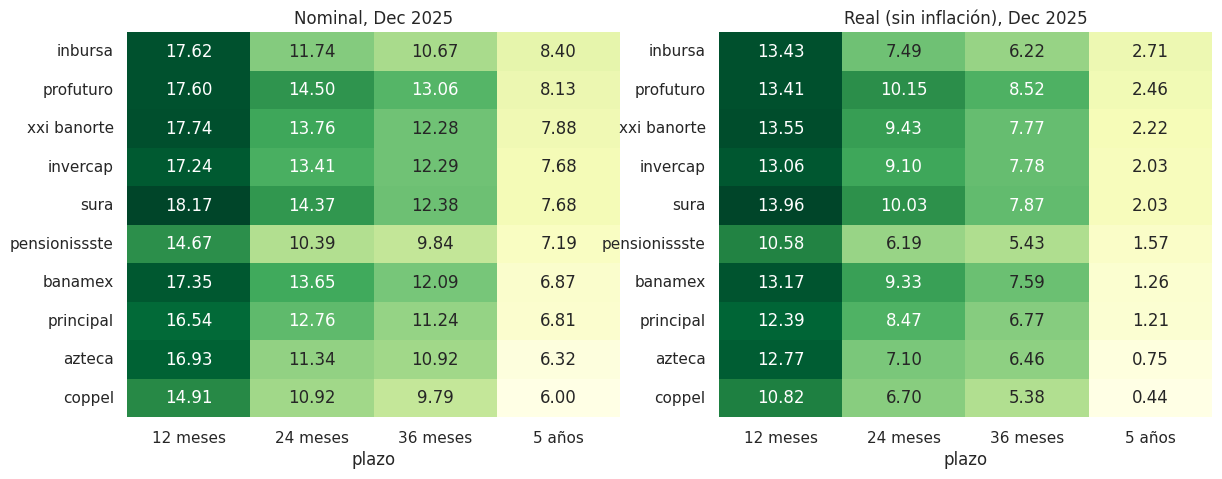

inflación anualizada en cada plazo: {'12 meses': np.float64(3.69), '24 meses': np.float64(3.95), '36 meses': np.float64(4.19), '5 años': np.float64(5.53)}


In [6]:
ultima = gen_r["fecha"].max()
hoy = (gen_r[(gen_r["fondo"] == "90-94") & (gen_r["fecha"] == ultima)]
       .pivot_table(index="afore", columns="plazo", values="real")[PLAZOS]
       .sort_values("5 años", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
nominal = (gen[(gen["fondo"] == "90-94") & (gen["fecha"] == ultima)]
           .pivot_table(index="afore", columns="plazo", values="monto")[PLAZOS].loc[hoy.index])
sns.heatmap(nominal, annot=True, fmt=".2f", cmap="YlGn", ax=axes[0], cbar=False)
axes[0].set_title(f"Nominal, {ultima:%b %Y}")
sns.heatmap(hoy, annot=True, fmt=".2f", cmap="YlGn", ax=axes[1], cbar=False)
axes[1].set_title(f"Real (sin inflación), {ultima:%b %Y}")
for a in axes:
    a.set_ylabel("")
guardar("02_heatmap_nominal_vs_real")
plt.show()
infl_hoy = {p: inflacion_anualizada(inpc, n).loc[ultima] for p, n in MESES_PLAZO.items()}
print("inflación anualizada en cada plazo:", {k: round(v, 2) for k, v in infl_hoy.items()})

## 6. ¿Cambia el ranking al descontar la inflación?
La inflación es la misma para todas las AFOREs en una fecha y plazo, así que el orden entre ellas no debería cambiar. Lo compruebo.

In [7]:
def spearman_nom_real(g):
    return g["monto"].corr(g["real"], method="spearman")

x = gen_r.dropna(subset=["real"])
corr = x.groupby(["fondo", "plazo", "fecha"]).apply(spearman_nom_real, include_groups=False)
print("correlación de Spearman entre ranking nominal y real (mínima de todos los casos):", round(corr.min(), 4))

correlación de Spearman entre ranking nominal y real (mínima de todos los casos): 1.0


Lo que sí cambia con la inflación es cuánto vale cada rendimiento. El orden es el mismo, pero los números reales son mucho más bajos que los nominales.

## 7. Rendimiento real por generación

In [8]:
# rendimiento real a 5 años, último dato disponible de cada fondo (promedio del sistema)
r5 = (sis_r[(sis_r["plazo"] == "5 años")].dropna(subset=["real"])
      .sort_values("fecha").groupby("fondo").tail(1).set_index("fondo")[["fecha", "monto", "inflacion", "real"]])
r5["fecha"] = r5["fecha"].dt.strftime("%Y-%m")
display(r5.round(2))

# en cuántos meses fue negativo el rendimiento real a 12 meses, por generación
neg12 = (sis_r[(sis_r["plazo"] == "12 meses")]
         .assign(negativo=lambda d: d["real"] < 0)
         .dropna(subset=["real"]).groupby("fondo")["negativo"].agg(["sum", "count"]))
neg12.columns = ["meses_real_negativo", "meses_con_dato"]
neg12["%"] = neg12["meses_real_negativo"] / neg12["meses_con_dato"] * 100
display(neg12.round(1))

,fecha,monto,inflacion,real
fondo,,,,
55-59,2024-07,5.98,5.58,0.38
60-64,2025-12,6.37,5.53,0.79
65-69,2025-12,6.91,5.53,1.30
90-94,2025-12,7.17,5.53,1.55
85-89,2025-12,7.25,5.53,1.63
pensiones,2025-12,6.80,5.53,1.20
70-74,2025-12,7.16,5.53,1.54
75-79,2025-12,7.28,5.53,1.65
80-84,2025-12,7.36,5.53,1.73


,meses_real_negativo,meses_con_dato,%
fondo,,,
55-59,26,56,46.4
60-64,24,73,32.9
65-69,20,73,27.4
70-74,19,73,26.0
75-79,18,73,24.7
80-84,18,73,24.7
85-89,18,73,24.7
90-94,18,73,24.7
95-99,0,17,0.0


## Qué encontré

Los plazos de 24, 36 meses y 5 años están anualizados: bajo esa hipótesis el error es de 0.007 puntos en promedio y bajo la de rendimiento acumulado es de 8.4 puntos. El INPC que capturé coincide con la inflación anual oficial de 2017 a 2024 (6.77, 4.83, 2.83, 3.15, 7.36, 7.82, 4.66 y 4.21%), y la de 2025 sale en 3.69%.

Descontar la inflación baja muchísimo los números. Por ejemplo, Inbursa en la SB 90-94 a dic 2025 tiene un rendimiento nominal de 17.62%, 11.74%, 10.67% y 8.40% a 12, 24, 36 meses y 5 años, y uno real de 13.43%, 7.49%, 6.22% y 2.71%. A 5 años el rendimiento real de la SB 90-94 va de 0.44% (Coppel) a 2.71% (Inbursa), y ninguna AFORE pasa de 3% real anual en ese plazo.

El rendimiento real a 12 meses fue negativo en 18 de los 22 meses entre enero de 2022 y octubre de 2023 (SB 90-94, promedio del sistema). El peor fue -16.1% en septiembre de 2022, cuando la caída del mercado coincidió con una inflación cercana a 9%. Los fondos más conservadores tuvieron más meses con rendimiento real negativo (33% en la SB 60-64 y en pensiones, contra 25% en la SB 90-94). Mi explicación probable es que su rendimiento nominal no alcanzó a compensar la inflación de 2022 y 2023 aunque en términos nominales cayeron menos. La SB 95-99 no se puede comparar porque solo tiene datos desde agosto de 2024.

El ranking entre AFOREs no cambia al descontar la inflación (correlación de 1.0 en todos los casos), porque la inflación es la misma para todas en una fecha y plazo. Cambia cuánto vale cada rendimiento, no el orden.

Limitaciones: el INPC viene de una tabla de un tercero (verificada contra cifras oficiales pero no bajada de INEGI), y el rendimiento real a 5 años solo existe desde 2021 porque mi INPC empieza en 2016.

## Pendiente
- Contrastar `data/inpc_mensual.csv` con la serie oficial de INEGI.
- Usar estos rendimientos reales en el simulador (notebook 04).